<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI RDF Database](https://github.com/Query-farm/vgi-rdf)

Transactional SQL tables stored as RDF graphs

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-rdf/blob/main/notebooks/01_follow_foreign_keys_across_query_models.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-rdf/blob/main/notebooks/README.md)

## Follow a line item through SQL and RDF

How many foreign-key steps connect a line item to its region, and do SQL joins and RDF paths agree on regional revenue? We build a small **synthetic USD ledger in a disposable local RDF database**, follow the same relationships through both interfaces, then test rollback.

The depth limit controls how far we inspect a path. It does not change the ledger or its revenue. No remote database or account is contacted; only the released worker and Python dependencies are downloaded.

In [1]:
MAX_DEPTH = 2  # Foreign-key edges, integer 1–3; experiment: 3

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.26":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.26"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("rdf")
import rdf_example as example  # noqa: E402 — download before import

example.configure(MAX_DEPTH, "MAX_DEPTH")
store = example.Store()
store_path = store.path
theme()
session = connect(globals())
native = session.connection
connection = example.TransactionSession(native)
%config SqlMagic.autocommit = False
%sql connection

#### Connect to the released worker

The literal command installs **v0.2.0** in an isolated Python 3.13 environment.
Only the database directory is generated: the companion owns it, temporarily
isolates inherited RDF storage settings and removes it at cleanup. Explicit
`database` makes the storage choice visible. The SQL adapter keeps all cells on
one native session so variables and transactions span cell boundaries.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'rdf' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-rdf@v0.2.0 vgi-rdf-worker',
 database '{{store_path}}');

,Success


### A ledger with explicit ownership

Each line item belongs to an order, each order to a customer, and each customer to a region. The −30 USD entry is an invented credit. Foreign keys are enforced by the real worker and also create RDF edges. These are local fixture writes; rerunning starts with a new database.

In [5]:
%%sql
CREATE TABLE rdf.main.regions(id INTEGER PRIMARY KEY, region VARCHAR NOT NULL);
CREATE TABLE rdf.main.customers(id INTEGER PRIMARY KEY, customer VARCHAR NOT NULL, region_id INTEGER REFERENCES rdf.main.regions(id));
CREATE TABLE rdf.main.orders(id INTEGER PRIMARY KEY, customer_id INTEGER REFERENCES rdf.main.customers(id));
CREATE TABLE rdf.main.lineitems(id INTEGER PRIMARY KEY, order_id INTEGER REFERENCES rdf.main.orders(id), amount_usd DECIMAL(12,2));
INSERT INTO rdf.main.regions VALUES (1,'North'),(2,'South');
INSERT INTO rdf.main.customers VALUES (1,'Aster',1),(2,'Briar',1),(3,'Cedar',2);
INSERT INTO rdf.main.orders VALUES (101,1),(102,2),(103,3),(104,1);
INSERT INTO rdf.main.lineitems VALUES (1001,101,120),(1002,101,80),(1003,102,90),(1004,103,200),(1005,103,-30),(1006,104,60);
CREATE TABLE ledger AS SELECT l.id AS lineitem_id,l.order_id,c.customer,r.region,l.amount_usd
FROM rdf.main.lineitems l JOIN rdf.main.orders o ON l.order_id=o.id
JOIN rdf.main.customers c ON o.customer_id=c.id JOIN rdf.main.regions r ON c.region_id=r.id;

,Count


In [6]:
%%sql ledger <<
SELECT * FROM ledger ORDER BY lineitem_id;

In [7]:
display(ledger)

,lineitem_id,order_id,customer,region,amount_usd
0,1001,101,Aster,North,120.0
1,1002,101,Aster,North,80.0
2,1003,102,Briar,North,90.0
3,1004,103,Cedar,South,200.0
4,1005,103,Cedar,South,-30.0
5,1006,104,Aster,North,60.0


### Stable row identities connect the two views

`rdf_rows` adds a stable resource IRI to ordinary typed rows. We materialize those identities once and construct the known SQL lineage for line item 1003. The IRI is taken from returned data, never invented from a presumed storage format. `SET VARIABLE` and explicit transactions use one native SQL session through the small notebook adapter.

In [8]:
%%sql
CREATE TABLE items AS SELECT * FROM rdf.main.rdf_rows('main','lineitems');
CREATE TABLE orders AS SELECT * FROM rdf.main.rdf_rows('main','orders');
CREATE TABLE customers AS SELECT * FROM rdf.main.rdf_rows('main','customers');
CREATE TABLE regions AS SELECT * FROM rdf.main.rdf_rows('main','regions');
CREATE TABLE lineage AS
SELECT 0 AS depth,'Line item 1003' AS label,l.__rdf_iri AS node FROM items l WHERE l.id=1003
UNION ALL SELECT 1,'Order ' || o.id,o.__rdf_iri FROM items l JOIN orders o ON l.order_id=o.id WHERE l.id=1003
UNION ALL SELECT 2,c.customer,c.__rdf_iri FROM items l JOIN orders o ON l.order_id=o.id JOIN customers c ON o.customer_id=c.id WHERE l.id=1003
UNION ALL SELECT 3,r.region,r.__rdf_iri FROM items l JOIN orders o ON l.order_id=o.id JOIN customers c ON o.customer_id=c.id JOIN regions r ON c.region_id=r.id WHERE l.id=1003;
SET VARIABLE start_iri = (SELECT node FROM lineage WHERE depth=0);
CREATE TABLE reachable AS SELECT * FROM rdf.main.rdf_reachable(getvariable('start_iri'),max_depth := {{MAX_DEPTH}});
CREATE TABLE path_view AS SELECT l.depth,l.label,l.node,(l.depth=0 OR r.node IS NOT NULL) AS reached
FROM lineage l LEFT JOIN reachable r USING(node);

,Count


In [9]:
%%sql path <<
SELECT depth,label,reached FROM path_view ORDER BY depth;

In [10]:
display(path)

,depth,label,reached
0,0,Line item 1003,True
1,1,Order 102,True
2,2,Briar,True
3,3,North,False


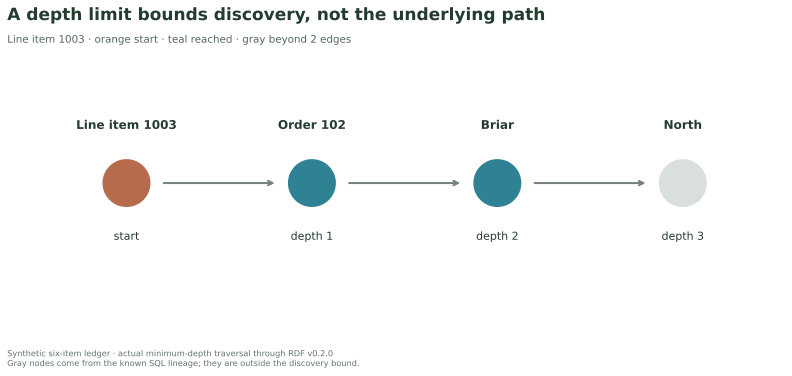

In [11]:
example.plot_lineage(path, MAX_DEPTH)

In [12]:
n = int(path.reached.sum()) - 1
last = path.loc[path.reached, "label"].iloc[-1]
prose(
    f"At depth **{MAX_DEPTH}**, the worker returns **{n}** distinct successor nodes, ending "
    f"at **{last}**. The start node is excluded by `rdf_reachable`. The full SQL path "
    f"remains visible in gray when the bound stops early; an omitted node is not evidence "
    f"that its relationship is absent."
)

At depth **2**, the worker returns **2** distinct successor nodes, ending at **Briar**. The start node is excluded by `rdf_reachable`. The full SQL path remains visible in gray when the bound stops early; an omitted node is not evidence that its relationship is absent.

### Reconcile a three-hop RDF path with SQL revenue

The named relationship graph contains the foreign-key edges. SPARQL follows three edges from line item to region; SQL then joins their returned IRIs back to typed rows and sums decimal USD amounts. This checks two query interfaces over one store, not two independent revenue sources. A multi-parent graph could duplicate paths, so we also verify one region per line item before aggregation.

In [13]:
%%sql
CREATE TABLE rdf_paths AS SELECT line.value AS item_iri, region.value AS region_iri
FROM rdf.main.rdf_sparql('SELECT ?line ?region WHERE { GRAPH <urn:vgi:rdf:relationships> { ?line ?p1 ?order . ?order ?p2 ?customer . ?customer ?p3 ?region } }');
CREATE TABLE sql_revenue AS SELECT region,sum(amount_usd) AS amount_usd,count(*) AS lineitems FROM ledger GROUP BY region;
CREATE TABLE graph_revenue AS SELECT r.region,sum(l.amount_usd) AS amount_usd,count(*) AS lineitems
FROM rdf_paths p JOIN items l ON p.item_iri=l.__rdf_iri JOIN regions r ON p.region_iri=r.__rdf_iri GROUP BY r.region;

,Count


In [14]:
%%sql revenue <<
SELECT s.region,s.amount_usd AS sql_usd,g.amount_usd AS rdf_usd,s.lineitems
FROM sql_revenue s JOIN graph_revenue g USING(region) ORDER BY region;

In [15]:
display(revenue)

,region,sql_usd,rdf_usd,lineitems
0,North,350.0,350.0,4
1,South,170.0,170.0,2


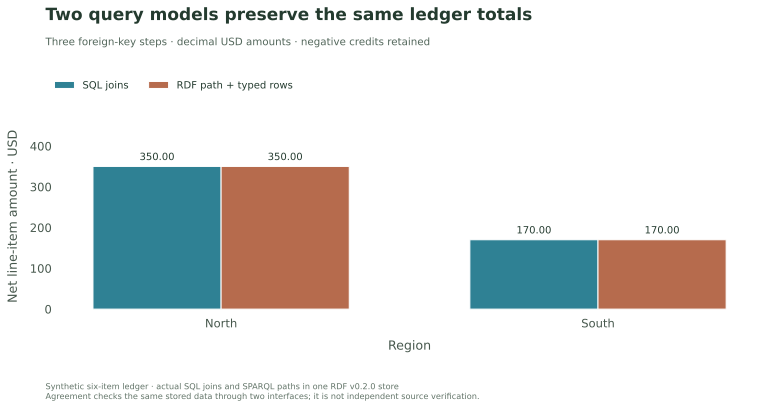

In [16]:
example.plot_revenue(revenue)

In [17]:
total = float(revenue.sql_usd.sum())
prose(
    f"Both interfaces total **USD {total:,.2f}** across **{int(revenue.lineitems.sum())}** "
    f"line items. The depth parameter affects only the earlier discovery call; this explicit "
    f"three-hop reconciliation is unchanged. The credit stays negative rather than being "
    f"discarded or treated as missing."
)

Both interfaces total **USD 520.00** across **6** line items. The depth parameter affects only the earlier discovery call; this explicit three-hop reconciliation is unchanged. The credit stays negative rather than being discarded or treated as missing.

### A local rollback control

Temporarily add USD 100 to the selected item, observe the tentative value, then roll back. This tests that the SQL write participates in the RDF transaction. The adapter keeps these statements on one native session; automatic JupySQL commits are disabled. No host staging table is written inside this transaction.

In [18]:
%%sql
BEGIN;
UPDATE rdf.main.lineitems SET amount_usd=amount_usd+100 WHERE id=1003;

,Count


In [19]:
%%sql preview <<
SELECT id,amount_usd FROM rdf.main.lineitems WHERE id=1003;

In [20]:
display(preview)

,id,amount_usd
0,1003,190.0


In [21]:
%%sql
ROLLBACK;

,Success


In [22]:
%%sql checks <<
SELECT 'one region per line item' AS check_name, count(*)=(SELECT count(*) FROM items) AND count(DISTINCT item_iri)=count(*) AS passed FROM rdf_paths
UNION ALL SELECT 'SQL and RDF totals match',NOT EXISTS ((SELECT * FROM sql_revenue EXCEPT ALL SELECT * FROM graph_revenue) UNION ALL (SELECT * FROM graph_revenue EXCEPT ALL SELECT * FROM sql_revenue))
UNION ALL SELECT 'bounded traversal matches SQL lineage',NOT EXISTS ((SELECT node,depth FROM reachable EXCEPT ALL SELECT node,depth FROM lineage WHERE depth BETWEEN 1 AND {{MAX_DEPTH}}) UNION ALL (SELECT node,depth FROM lineage WHERE depth BETWEEN 1 AND {{MAX_DEPTH}} EXCEPT ALL SELECT node,depth FROM reachable))
UNION ALL SELECT 'unique stable identities',count(DISTINCT __rdf_iri)=count(*) FROM items
UNION ALL SELECT 'non-null amounts',count(amount_usd)=count(*) FROM items
UNION ALL SELECT 'rollback restores rows and identities',NOT EXISTS ((SELECT * FROM rdf.main.rdf_rows('main','lineitems') EXCEPT ALL SELECT * FROM items) UNION ALL (SELECT * FROM items EXCEPT ALL SELECT * FROM rdf.main.rdf_rows('main','lineitems')))
UNION ALL SELECT 'retained negative credit',count(*)>0 FROM items WHERE amount_usd<0
UNION ALL SELECT 'path contains start once',count(*)=1 FROM lineage WHERE depth=0
ORDER BY check_name;

In [23]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
assert float(preview.amount_usd.iloc[0]) == float(ledger.loc[ledger.lineitem_id == 1003, "amount_usd"].iloc[0]) + 100
prose(
    f"All **{len(checks) + 1}** checks pass, including the tentative USD 100 change and "
    f"complete row/identity restoration after rollback."
)

,check_name,passed
0,SQL and RDF totals match,True
1,bounded traversal matches SQL lineage,True
2,non-null amounts,True
3,one region per line item,True
4,path contains start once,True
5,retained negative credit,True
6,rollback restores rows and identities,True
7,unique stable identities,True


All **9** checks pass, including the tentative USD 100 change and complete row/identity restoration after rollback.

### Experiment: let discovery reach the region

Change `MAX_DEPTH` from **2 to 3**, restart, and run all; or run the README command for a separate copy. Predict one more reached node in the lineage figure. Compare the returned nodes, not only the number of rows. The regional revenue figure and ledger should stay identical because no data or three-hop reconciliation query changed.

Reset to **2** afterward. Bounded reachability reports minimum edge depth and excludes the start; it is neither a monetary allocation nor a completeness claim about a larger unknown graph.

In [24]:
assert native.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
native.execute("DETACH rdf")
session.close()
store.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-rdf](https://github.com/Query-farm/vgi-rdf)